# 1. Ingesta y calidad de datos del 311

**Pregunta del proyecto:** ¿cuánto tarda Nueva York en resolver las solicitudes ciudadanas del 311 y qué lo explica?

Este notebook revisa la descarga (API Socrata de NYC Open Data, dataset `erm2-nwe9`), las reglas de limpieza y,
sobre todo, cómo se definen el **evento** (cierre) y la **censura** (solicitud abierta en la fecha de corte).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from nyc311.config import ARCHIVO_LIMPIO, ARCHIVO_RESULTADOS, DIR_FIGURAS, DIR_TABLAS

res = json.loads(ARCHIVO_RESULTADOS.read_text(encoding="utf-8"))
tabla = lambda nombre: pd.read_csv(DIR_TABLAS / f"{nombre}.csv")
figura = lambda nombre: display(Image(filename=str(DIR_FIGURAS / nombre)))

## 1.1 Qué se descargó

La descarga (`python descargar_datos.py`) pide solo 10 columnas, un mes por tarea, en páginas de 50.000 filas
ordenadas por `unique_key`, con reintentos y caché por página (reanudable). La **fecha de corte** queda fija en el
manifiesto: es la `created_date` más reciente publicada al empezar la descarga.

In [2]:
manifiesto = json.loads((RAIZ / "data" / "raw" / "manifiesto_descarga.json").read_text(encoding="utf-8"))
{k: v for k, v in manifiesto.items() if k != "columnas"}

{'fuente': 'https://data.cityofnewyork.us/resource/erm2-nwe9.csv',
 'mes_inicio': '2024-10',
 'mes_fin': '2026-09',
 'fecha_corte': '2026-10-26T01:36:17',
 'inicio_descarga_utc': '2026-10-27T12:35:13+00:00'}

In [3]:
cal = res["calidad"]
pd.Series({k: v for k, v in cal.items() if not isinstance(v, dict)}, name="valor").to_frame()

,valor
filas_crudas,7559591
fecha_corte,2026-10-26 01:36:17
duplicados_unique_key,0
sin_fecha_creacion_valida,0
cierre_antes_de_apertura,2082
cerradas_sin_fecha_cierre,12831
cierre_posterior_al_corte,34
fecha_cierre_con_estado_abierto,18724
filas_limpias,7544678
filas_descartadas,14913


## 1.2 Reglas de limpieza

| Problema | Decisión | Por qué |
| --- | --- | --- |
| `closed_date` < `created_date` | Se descarta | La duración sería negativa: no hay forma de saber la verdadera |
| `status = Closed` sin `closed_date` | Se descarta | Sabemos que cerró, pero no cuándo |
| Fecha de cierre con estado abierto | Censura al corte | El estado es lo más reciente: probablemente se reabrió |
| Cierre posterior al corte | Censura al corte | En la fecha de corte todavía estaba abierta |
| Cierre en el mismo segundo | Se conserva (duración 0) | Son cierres administrativos reales (p. ej. derivaciones) |
| Borough `Unspecified`, ZIP fuera de NYC | Se conservan con «SIN DATO» / nulo | Solo se excluyen de los análisis territoriales |

In [4]:
pd.Series(cal["cierre_antes_de_apertura_por_agencia"], name="cierres antes de la apertura").to_frame()

,cierres antes de la apertura
DOT,1313
DEP,628
NYPD,134
DSNY,7


## 1.3 La tabla analítica: duración y censura

Cada fila tiene `duracion_dias` y `evento` (1 = cerrada, 0 = censurada). Para una censurada la duración es
`fecha_corte − creada`: solo sabemos que tardó **al menos** eso.

In [5]:
df = pd.read_parquet(ARCHIVO_LIMPIO, columns=["unique_key", "creada", "cerrada", "agencia", "tipo_queja", "borough",
                                              "canal", "estado", "duracion_dias", "evento"])
print(f"{len(df):,} solicitudes · {df['evento'].mean():.2%} cerradas al corte")
df.sample(6, random_state=1)

7,544,678 solicitudes · 97.32% cerradas al corte


,unique_key,creada,cerrada,agencia,tipo_queja,borough,canal,estado,duracion_dias,evento
1510512,64224749,2025-03-01 11:07:26,2025-03-01 14:16:12,NYPD,Illegal Parking,MANHATTAN,Web,Closed,0.131,1
1636606,64360002,2025-03-14 17:43:55,2025-03-14 17:57:07,DSNY,Vendor Enforcement,QUEENS,Web,Closed,0.009,1
2355897,65126707,2025-06-02 00:17:20,2025-06-02 02:16:29,NYPD,Illegal Parking,QUEENS,Web,Closed,0.083,1
3086369,65843577,2025-08-13 15:36:00,NaT,DOT,Traffic Signal Condition,MANHATTAN,Otro/desconocido,Assigned,438.417,0
3456479,66200292,2025-09-18 14:22:31,2025-09-24 13:48:54,HPD,PAINT/PLASTER,MANHATTAN,Teléfono,Closed,5.977,1
611789,63273107,2024-12-02 22:49:52,2024-12-04 20:05:21,HPD,HEAT/HOT WATER,QUEENS,Web,Closed,1.886,1


In [6]:
from nyc311.limpieza import validar_tabla
validar_tabla(df)  # lista vacía = sin duplicados, sin duraciones negativas, eventos coherentes

[]

In [7]:
por_agencia = (df.groupby("agencia", observed=True)["evento"]
                 .agg(solicitudes="size", pct_censuradas=lambda e: 100 * (1 - e.mean()))
                 .sort_values("solicitudes", ascending=False))
por_agencia.head(12)

,solicitudes,pct_censuradas
agencia,,
NYPD,3404989,0.020
HPD,1647990,1.956
DSNY,686984,1.098
DOT,489985,4.719
DEP,427705,1.718
DPR,250070,23.085
DOB,220866,6.269
DOHMH,169211,6.414
DHS,88289,2.458


La censura global es baja, pero **no se reparte igual**: en las agencias lentas (Parques, TLC, EDC) una parte
grande sigue abierta. Promediar solo las cerradas de esas agencias descarta justo los casos más lentos: ese es el
sesgo que el notebook 2 cuantifica.

La censura aquí es **administrativa**: solo la produce el corte. Ninguna solicitud «desaparece» antes, así que la
censura es no informativa (supuesto clave de Kaplan-Meier y Cox).

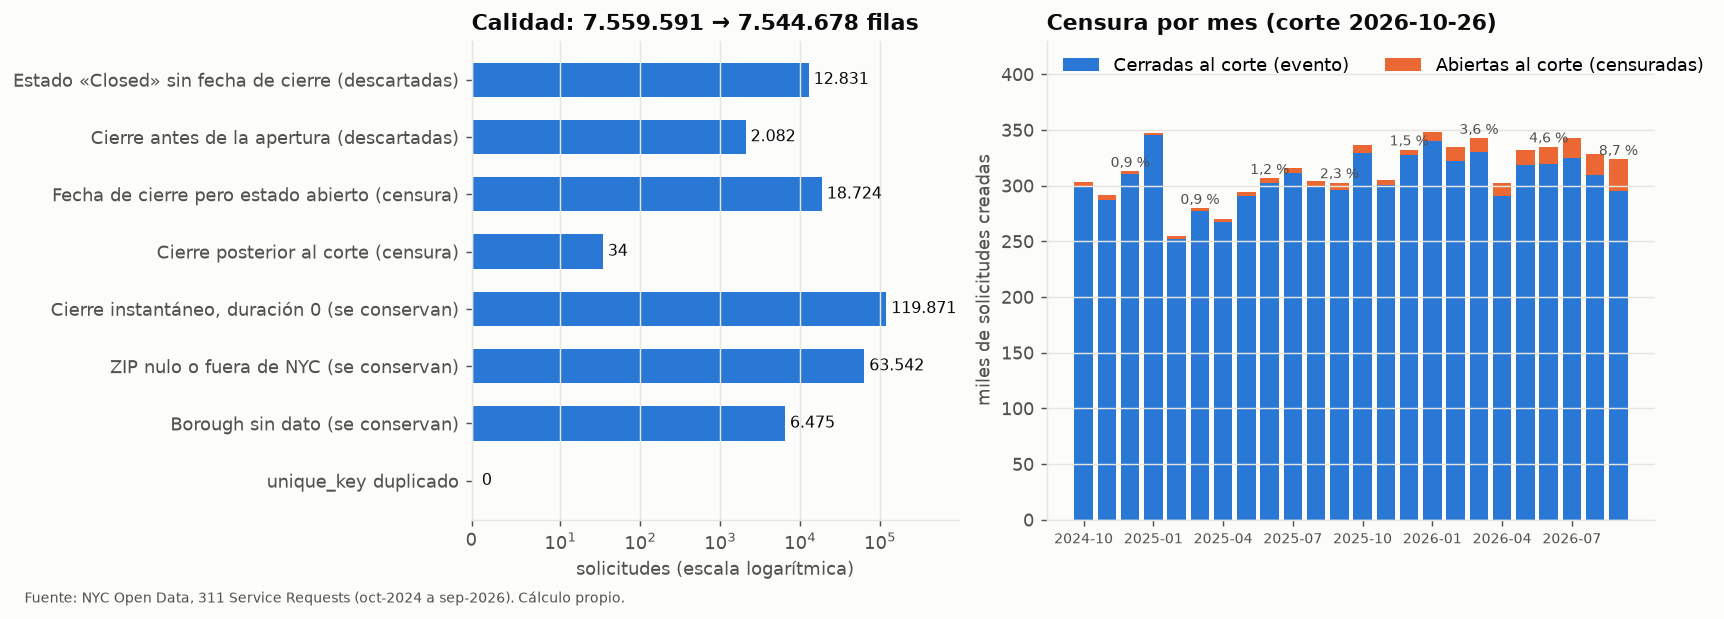

In [8]:
figura("01_calidad_y_censura.png")